# Multiclass Classification Metrics with MNIST

This notebook compares Logistic Regression and Decision Tree classifiers on handwritten digits `0` through `9`. Each example is a 28 x 28 grayscale image represented by 784 pixel values, and its `label` is the correct digit.

The notebook loads the local Kaggle CSV files, prepares the image features and labels, trains both models, and evaluates their predictions on the test set. Kaggle dataset links and download instructions are included in the dataset section below.

## 1. Imports

NumPy and pandas handle array and table operations. The scikit-learn metric functions imported here will compare model predictions with the true digit labels later.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

## 2. Locate the Dataset

`Path` checks for the `datasets` folder relative to either the notebook folder or repository root. The following code cell stops with a clear error if neither expected location exists.

Download the MNIST CSV files from Kaggle:

- [Training dataset: mnist_train.csv](https://www.kaggle.com/datasets/oddrationale/mnist-in-csv?select=mnist_train.csv)
- [Test dataset: mnist_test.csv](https://www.kaggle.com/datasets/oddrationale/mnist-in-csv?select=mnist_test.csv)

To download and extract both files into the expected folder from the repository root, install the Kaggle CLI, configure your Kaggle API credentials, then run:

```bash
python -m pip install kaggle
mkdir -p "09 Evaluation Metrics in ML/datasets"
kaggle datasets download -d oddrationale/mnist-in-csv -p "09 Evaluation Metrics in ML/datasets" --unzip
```

Kaggle authentication is required. Do not commit or share your API token.

In [2]:
from pathlib import Path

# Use the local MNIST CSV files in this project's datasets folder.
data_dir = Path("datasets")
if not data_dir.is_dir():
    data_dir = Path("09 Evaluation Metrics in ML") / "datasets"
if not data_dir.is_dir():
    raise FileNotFoundError("Could not find the local datasets folder.")

## 3. Load the CSV Files

Read the local training and test CSV files into pandas DataFrames. Each row is one labeled image: the `label` column is the digit, and the remaining 784 columns are its pixel intensities.

In [3]:
train_df = pd.read_csv(data_dir / "mnist_train.csv")
test_df = pd.read_csv(data_dir / "mnist_test.csv")


## 4. Preview the Training Data

`head()` displays the first five rows so you can inspect the label and pixel columns before preparing the data.

In [4]:
train_df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 5. Check the Dataset Dimensions

The DataFrame shape is `(number of images, number of columns)`. For the full training CSV, expect 60,000 rows and 785 columns: one label plus 784 pixels.

In [5]:
train_df.shape

(60000, 785)

## 6. Check the Digit Class Distribution

Count how many training examples belong to each digit. The proportions help explain why macro averaging gives every class equal weight while weighted averaging reflects class support.

,Training examples,Proportion
Digit,,
0,5923,9.9%
1,6742,11.2%
2,5958,9.9%
3,6131,10.2%
4,5842,9.7%
5,5421,9.0%
6,5918,9.9%
7,6265,10.4%
8,5851,9.8%


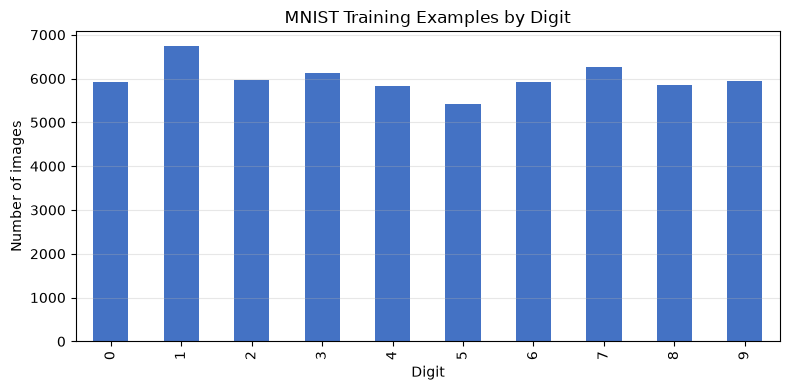

In [17]:
class_counts = train_df["label"].value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Training examples": class_counts,
    "Proportion": (class_counts / len(train_df)).map(lambda proportion: f"{proportion:.1%}"),
})
class_distribution.index.name = "Digit"
display(class_distribution)

ax = class_counts.plot(kind="bar", figsize=(8, 4), color="#4472C4")
ax.set_title("MNIST Training Examples by Digit")
ax.set_xlabel("Digit")
ax.set_ylabel("Number of images")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Visualize Five Training Images

Each row contains 784 pixel values, which are reshaped into a 28 x 28 image because $28 \times 28 = 784$. The plot shows five examples and each image's `label` (the correct digit). Pixel intensities run from 0 (black) to 255 (white).

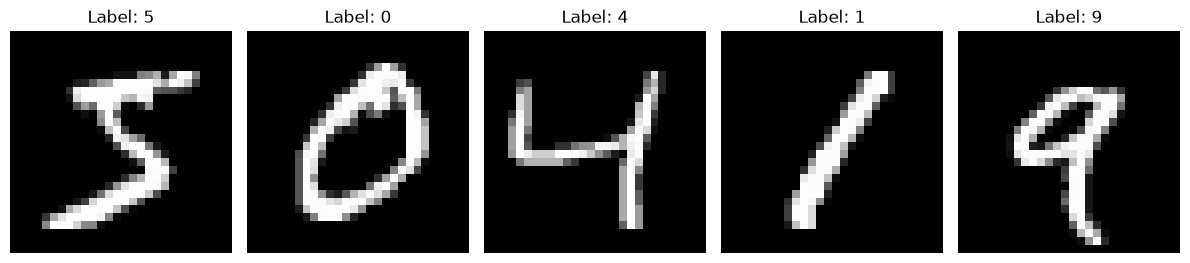

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, (_, sample) in zip(axes, train_df.iloc[:5].iterrows()):
    image = sample.drop(labels="label").to_numpy().reshape(28, 28)
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {sample['label']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Prepare Features and Labels

`X` contains the 784 pixel features; `y` contains the digit label. Training and test CSVs already provide separate splits. Normalize each pixel using $x_{scaled} = x / 255$, mapping its original intensity from 0-255 into 0-1. The printed shapes confirm the number of images and features.

In [16]:

X_train = train_df.drop(columns="label").to_numpy(dtype=np.float32) / 255.0
y_train = train_df["label"].to_numpy(dtype=int)
X_test = test_df.drop(columns="label").to_numpy(dtype=np.float32) / 255.0
y_test = test_df["label"].to_numpy(dtype=int)

print(f"Training data: {X_train.shape}, labels: {y_train.shape}")
print(f"Test data: {X_test.shape}, labels: {y_test.shape}")
print(f"Digit classes: {np.unique(y_train)}")

Training data: (60000, 784), labels: (60000,)
Test data: (10000, 784), labels: (10000,)
Digit classes: [0 1 2 3 4 5 6 7 8 9]


## 9. Choose the Classifiers

Import two scikit-learn estimators for comparison: multinomial Logistic Regression and a Decision Tree. Both receive the same training examples and are evaluated against the same held-out test set.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

## 10. Train Logistic Regression

`.fit(X_train, y_train)` learns patterns linking pixel intensities to digit labels. `.predict(X_test)` predicts a digit for each official test image. These predictions are later compared with `y_test`.

In [25]:
classification_logistic_regression = LogisticRegression(max_iter=300)
classification_logistic_regression.fit(X_train, y_train)
classification_logistic_regression_predictions = classification_logistic_regression.predict(X_test)

## 11. Train the Decision Tree

Fit the tree on the same training split and generate predictions for the same test images. Using identical data splits makes the model comparison fair.

In [26]:
classification_decision_tree = DecisionTreeClassifier()
classification_decision_tree.fit(X_train, y_train)
classification_decision_tree_predictions = classification_decision_tree.predict(X_test)

## 11. Inspect Misclassified Images

For each model, plot up to five test images it classified incorrectly. The actual and predicted labels help show which digit shapes caused errors; the image pixels are reshaped back to 28 x 28 for display.

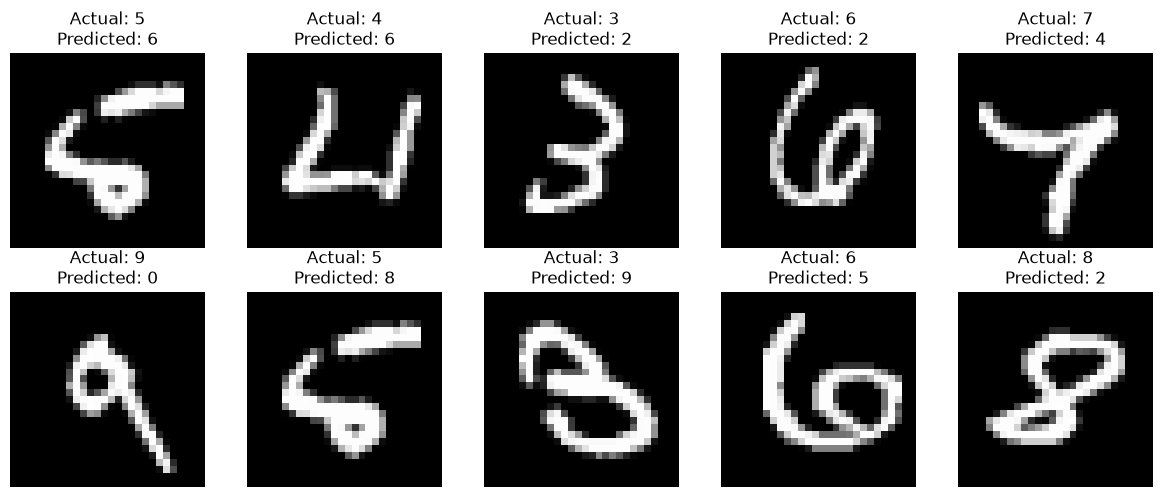

In [27]:
model_predictions = [
    classification_logistic_regression_predictions,
    classification_decision_tree_predictions,
]
model_names = ["Logistic Regression", "Decision Tree"]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for row_axes, model_name, predictions in zip(axes, model_names, model_predictions):
    error_indices = np.flatnonzero(predictions != y_test)[:5]
    for ax, index in zip(row_axes, error_indices):
        ax.imshow(X_test[index].reshape(28, 28), cmap="gray")
        ax.set_title(f"Actual: {y_test[index]}\nPredicted: {predictions[index]}")
        ax.axis("off")
    for ax in row_axes[len(error_indices):]:
        ax.axis("off")
    row_axes[0].set_ylabel(model_name)

plt.tight_layout()
plt.show()

## 12. Evaluate Logistic Regression

For each digit class $k$, define $TP_k$ as correctly predicted examples of class $k$, $FP_k$ as other digits incorrectly predicted as $k$, and $FN_k$ as class-$k$ examples predicted as another digit. The per-class metrics are:

$$P_k = \frac{TP_k}{TP_k + FP_k}, \qquad R_k = \frac{TP_k}{TP_k + FN_k}, \qquad F1_k = \frac{2P_kR_k}{P_k + R_k}$$

Overall accuracy is the fraction of all test images classified correctly:

$$Accuracy = \frac{\sum_{i=1}^{N} \mathbf{1}(y_i = \hat{y}_i)}{N}$$

### Macro Average

Macro averaging calculates each class's metric, then gives all $K=10$ digit classes equal weight:

$$Precision_{macro} = \frac{1}{K}\sum_{k=1}^{K} P_k = \frac{1}{K}\sum_{k=1}^{K}\frac{TP_k}{TP_k + FP_k}$$

$$Recall_{macro} = \frac{1}{K}\sum_{k=1}^{K} R_k = \frac{1}{K}\sum_{k=1}^{K}\frac{TP_k}{TP_k + FN_k}$$

$$F1_{macro} = \frac{1}{K}\sum_{k=1}^{K} F1_k = \frac{1}{K}\sum_{k=1}^{K}\frac{2P_kR_k}{P_k + R_k}$$

Every class contributes equally, regardless of how many examples it has.

### Weighted Average

Weighted averaging weights each class's metric by its support $n_k$, the number of actual test examples in class $k$. Let $N = \sum_{k=1}^{K} n_k$:

$$Precision_{weighted} = \frac{\sum_{k=1}^{K} n_k P_k}{N}$$

$$Recall_{weighted} = \frac{\sum_{k=1}^{K} n_k R_k}{N}$$

$$F1_{weighted} = \frac{\sum_{k=1}^{K} n_k F1_k}{N}$$

Unlike macro averaging, larger classes contribute more to a weighted score. Weighted F1 is the support-weighted average of class F1 scores; it is not the harmonic mean of weighted precision and weighted recall.

The confusion matrix has actual classes in rows and predicted classes in columns. `zero_division=0` returns zero if a class precision or recall would otherwise be undefined. The metric tables are rounded for readability.

Logistic Regression - Metrics


,Score
Accuracy,0.9260
Precision (macro),0.9250
Recall (macro),0.9249
F1 score (macro),0.9249
Precision (weighted),0.9258
Recall (weighted),0.9260
F1 score (weighted),0.9258


Confusion matrix (counts)


Predicted,0,1,2,3,4,5,6,7,8,9
Actual,,,,,,,,,,
0,957,0,1,4,1,9,4,3,1,0
1,0,1111,4,2,0,2,3,2,11,0
2,6,9,931,15,10,3,12,9,33,4
3,4,1,16,922,1,25,2,10,20,9
4,1,3,7,3,921,0,6,4,6,31
5,9,2,3,35,8,779,15,6,31,4
6,8,3,8,2,7,16,911,2,1,0
7,1,7,24,6,6,1,0,949,1,33
8,9,11,7,21,8,28,14,10,854,12


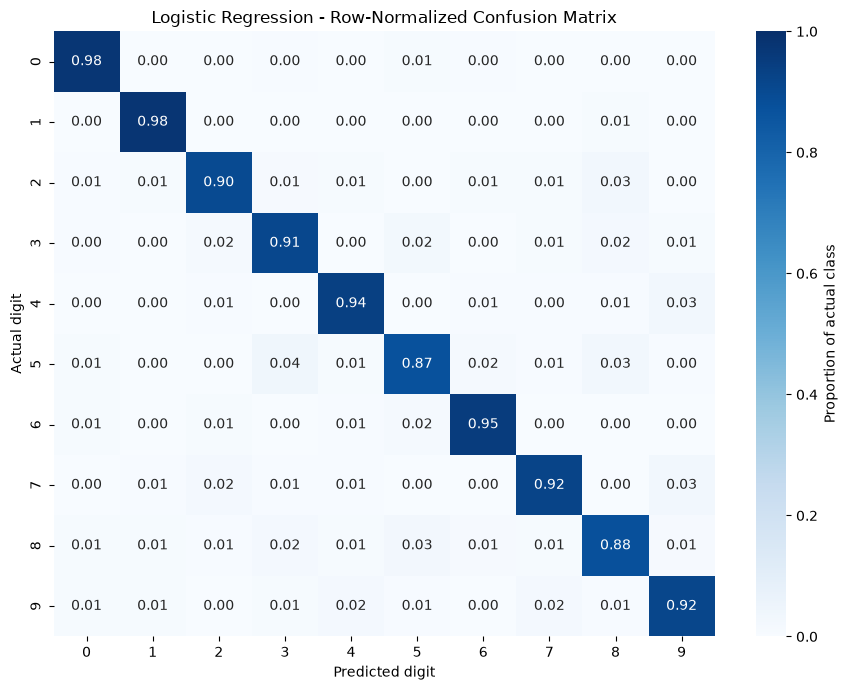

Classification report


,precision,recall,f1-score,support
0,0.953,0.977,0.965,980.000
1,0.962,0.979,0.970,1135.000
2,0.929,0.902,0.915,1032.000
3,0.904,0.913,0.908,1010.000
4,0.937,0.938,0.937,982.000
5,0.895,0.873,0.884,892.000
6,0.942,0.951,0.946,958.000
7,0.933,0.923,0.928,1028.000
8,0.886,0.877,0.881,974.000
9,0.909,0.917,0.913,1009.000


In [28]:
# Logistic Regression Metrics
accuracy_logistic = accuracy_score(y_test, classification_logistic_regression_predictions)
precision_logistic_macro = precision_score(y_test, classification_logistic_regression_predictions, average="macro", zero_division=0)
recall_logistic_macro = recall_score(y_test, classification_logistic_regression_predictions, average="macro", zero_division=0)
f1_logistic_macro = f1_score(y_test, classification_logistic_regression_predictions, average="macro", zero_division=0)
precision_logistic_weighted = precision_score(y_test, classification_logistic_regression_predictions, average="weighted", zero_division=0)
recall_logistic_weighted = recall_score(y_test, classification_logistic_regression_predictions, average="weighted", zero_division=0)
f1_logistic_weighted = f1_score(y_test, classification_logistic_regression_predictions, average="weighted", zero_division=0)

logistic_metrics = pd.DataFrame(
    {"Score": {
        "Accuracy": accuracy_logistic,
        "Precision (macro)": precision_logistic_macro,
        "Recall (macro)": recall_logistic_macro,
        "F1 score (macro)": f1_logistic_macro,
        "Precision (weighted)": precision_logistic_weighted,
        "Recall (weighted)": recall_logistic_weighted,
        "F1 score (weighted)": f1_logistic_weighted,
    }}
)
print("Logistic Regression - Metrics")
display(logistic_metrics.round(4))

logistic_confusion = pd.DataFrame(
    confusion_matrix(y_test, classification_logistic_regression_predictions, labels=list(range(10))),
    index=pd.Index(range(10), name="Actual"),
    columns=pd.Index(range(10), name="Predicted"),
)
print("Confusion matrix (counts)")
display(logistic_confusion)

logistic_confusion_normalized = logistic_confusion.div(logistic_confusion.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    logistic_confusion_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Proportion of actual class"},
    ax=ax,
)
ax.set_title("Logistic Regression - Row-Normalized Confusion Matrix")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("Actual digit")
plt.tight_layout()
plt.show()

logistic_report = pd.DataFrame(
    classification_report(
        y_test,
        classification_logistic_regression_predictions,
        labels=list(range(10)),
        output_dict=True,
        zero_division=0,
    )
).T
print("Classification report")
display(logistic_report.round(3))

## 13. Evaluate the Decision Tree

The same accuracy, per-class, macro, and weighted formulas are applied to the Decision Tree predictions. Comparing the rounded score tables shows overall performance, while the confusion matrix and classification report help identify which digits are most often confused.

Decision Tree - Metrics


,Score
Accuracy,0.8781
Precision (macro),0.8767
Recall (macro),0.8765
F1 score (macro),0.8765
Precision (weighted),0.8780
Recall (weighted),0.8781
F1 score (weighted),0.8780


Confusion matrix (counts)


Predicted,0,1,2,3,4,5,6,7,8,9
Actual,,,,,,,,,,
0,909,0,15,10,4,10,11,4,9,8
1,1,1093,12,4,2,2,7,3,10,1
2,8,14,872,45,14,14,14,24,20,7
3,7,5,33,865,8,38,2,7,26,19
4,6,3,7,8,869,9,20,7,14,39
5,20,8,2,44,5,742,24,6,25,16
6,14,6,10,10,20,24,849,2,18,5
7,2,12,22,13,8,6,1,933,8,23
8,12,4,35,33,19,29,17,10,788,27


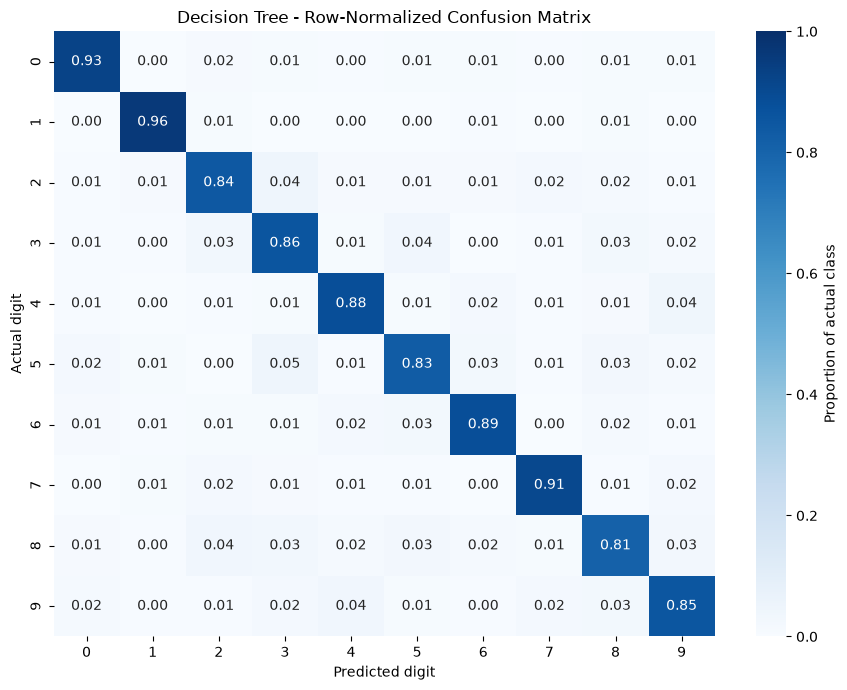

Classification report


,precision,recall,f1-score,support
0,0.913,0.928,0.920,980.000
1,0.951,0.963,0.957,1135.000
2,0.859,0.845,0.852,1032.000
3,0.822,0.856,0.839,1010.000
4,0.881,0.885,0.883,982.000
5,0.839,0.832,0.836,892.000
6,0.894,0.886,0.890,958.000
7,0.917,0.908,0.912,1028.000
8,0.835,0.809,0.822,974.000
9,0.856,0.853,0.855,1009.000


In [29]:
# Decision Tree Metrics
accuracy_decision_tree = accuracy_score(y_test, classification_decision_tree_predictions)
precision_decision_tree_macro = precision_score(y_test, classification_decision_tree_predictions, average="macro", zero_division=0)
recall_decision_tree_macro = recall_score(y_test, classification_decision_tree_predictions, average="macro", zero_division=0)
f1_decision_tree_macro = f1_score(y_test, classification_decision_tree_predictions, average="macro", zero_division=0)
precision_decision_tree_weighted = precision_score(y_test, classification_decision_tree_predictions, average="weighted", zero_division=0)
recall_decision_tree_weighted = recall_score(y_test, classification_decision_tree_predictions, average="weighted", zero_division=0)
f1_decision_tree_weighted = f1_score(y_test, classification_decision_tree_predictions, average="weighted", zero_division=0)

decision_tree_metrics = pd.DataFrame(
    {"Score": {
        "Accuracy": accuracy_decision_tree,
        "Precision (macro)": precision_decision_tree_macro,
        "Recall (macro)": recall_decision_tree_macro,
        "F1 score (macro)": f1_decision_tree_macro,
        "Precision (weighted)": precision_decision_tree_weighted,
        "Recall (weighted)": recall_decision_tree_weighted,
        "F1 score (weighted)": f1_decision_tree_weighted,
    }}
)
print("Decision Tree - Metrics")
display(decision_tree_metrics.round(4))

decision_tree_confusion = pd.DataFrame(
    confusion_matrix(y_test, classification_decision_tree_predictions, labels=list(range(10))),
    index=pd.Index(range(10), name="Actual"),
    columns=pd.Index(range(10), name="Predicted"),
)
print("Confusion matrix (counts)")
display(decision_tree_confusion)

decision_tree_confusion_normalized = decision_tree_confusion.div(
    decision_tree_confusion.sum(axis=1), axis=0
)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    decision_tree_confusion_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Proportion of actual class"},
    ax=ax,
)
ax.set_title("Decision Tree - Row-Normalized Confusion Matrix")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("Actual digit")
plt.tight_layout()
plt.show()

decision_tree_report = pd.DataFrame(
    classification_report(
        y_test,
        classification_decision_tree_predictions,
        labels=list(range(10)),
        output_dict=True,
        zero_division=0,
    )
).T
print("Classification report")
display(decision_tree_report.round(3))

## 14. Compare the Classifiers

Compare accuracy and macro/weighted precision, recall, and F1 side by side. Macro scores treat every digit equally; weighted scores account for each digit's support. Use the per-class reports and heatmaps above to investigate differences.

In [30]:
model_comparison = pd.DataFrame(
    {
        "Accuracy": [accuracy_logistic, accuracy_decision_tree],
        "Precision (macro)": [precision_logistic_macro, precision_decision_tree_macro],
        "Recall (macro)": [recall_logistic_macro, recall_decision_tree_macro],
        "F1 (macro)": [f1_logistic_macro, f1_decision_tree_macro],
        "Precision (weighted)": [precision_logistic_weighted, precision_decision_tree_weighted],
        "Recall (weighted)": [recall_logistic_weighted, recall_decision_tree_weighted],
        "F1 (weighted)": [f1_logistic_weighted, f1_decision_tree_weighted],
    },
    index=["Logistic Regression", "Decision Tree"],
)
display(model_comparison.round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
Logistic Regression,0.9260,0.9250,0.9249,0.9249,0.9258,0.9260,0.9258
Decision Tree,0.8781,0.8767,0.8765,0.8765,0.8780,0.8781,0.8780
